In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def load_data(path):
    return pd.read_csv(path)

def check_data(df):
    print("Shape:", df.shape)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Numeric cols:", df.select_dtypes(include="number").shape[1],
          "| Text cols:", df.select_dtypes(exclude="number").shape[1])


In [3]:
def visualize_data(df):
    # 1. Price histograms
    df["price"].plot(kind="hist", bins=20, edgecolor="black", title="Price Distribution", figsize=(5, 4))
    plt.xlabel("Price")
    plt.tight_layout()
    plt.show()

    # 2. Scatter plots
    cols = ["enginesize", "horsepower", "curbweight", "citympg"]
    for col in cols:
        df.plot(kind="scatter", x=col, y="price", title=col + " vs Price", figsize=(5, 4))
        plt.tight_layout()
        plt.show()

    # 3. Correlation bar chart 
    corr = df.drop(columns="car_ID").select_dtypes(include="number").corr()["price"]
    corr = corr.drop("price").sort_values()
    corr.plot(kind="barh", figsize=(8, 6), title="Correlation with Price")
    plt.xlabel("Correlation")
    plt.tight_layout()
    plt.show()

    # 4. Boxplots by category
    cols = ["carbody", "fueltype", "aspiration"]
    for col in cols:
        df.boxplot(column="price", by=col, figsize=(6, 4))
        plt.title("Price by " + col)
        plt.suptitle("")
        plt.xlabel(col)
        plt.ylabel("Price")
        plt.tight_layout()
        plt.show()

In [4]:
def encode_features(raw):
    df = raw.drop(columns=["car_ID"]).copy()
    df["brand"] = df["CarName"].str.split().str[0].str.lower()
    df = df.drop(columns=["CarName"])

    # binary columns
    df["fueltype"] = df["fueltype"].map({"gas": 0, "diesel": 1})
    df["aspiration"] = df["aspiration"].map({"std": 0, "turbo": 1})
    df["doornumber"] = df["doornumber"].map({"two": 2, "four": 4})
    df["enginelocation"] = df["enginelocation"].map({"front": 0, "rear": 1})

    # ordinal column
    df["cylindernumber"] = df["cylindernumber"].map({
        "two": 2, "three": 3, "four": 4, "five": 5,
        "six": 6, "eight": 8, "twelve": 12})

    # one-hot encode the remaining text columns
    cats = ["carbody", "drivewheel", "enginetype", "fuelsystem", "brand"]
    return pd.get_dummies(df, columns=cats, drop_first=True, dtype=float)

def split_xy(df, seed=7):
    X = df.drop(columns="price").to_numpy(dtype=float)
    y = df["price"].to_numpy(dtype=float).reshape(-1, 1)
    np.random.seed(seed)
    idx = np.random.permutation(len(X))
    n_test = int(0.2 * len(X))
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

def standardize(X_train, X_test):
    mu, sd = X_train.mean(axis=0), X_train.std(axis=0)
    sd[sd == 0] = 1
    return (X_train - mu) / sd, (X_test - mu) / sd

def add_bias(X):
    return np.hstack([np.ones((len(X), 1)), X])

In [5]:
def predict(X, w):
    return X @ w

def gradient_descent(X, y, lr=0.01, epochs=500):
    w = np.zeros((X.shape[1], 1))     # w[0] is the intercept w0, w[1:] are the feature weights
    losses = []
    for _ in range(epochs):
        error = predict(X, w) - y
        losses.append((error ** 2).mean() / 2)

        grad = X.T @ error / len(y)
        w = w - lr * grad
    return w, losses

In [6]:
def mae(y, y_hat):
    return np.abs(y - y_hat).mean()

def rmse(y, y_hat):
    return np.sqrt(((y - y_hat) ** 2).mean())

def r2_score(y, y_hat):
    ss_res = ((y - y_hat) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot

def evaluate(y, y_hat):
    return {"MAE": mae(y, y_hat), "RMSE": rmse(y, y_hat), "R2": r2_score(y, y_hat)}

In [7]:
def plot_loss(losses, title="Loss vs epoch (log scale)"):
    pd.Series(losses).plot(title=title, xlabel="Epoch", ylabel="Loss", logy=True)
    plt.show()

def plot_predictions(y, y_hat, title="Actual vs predicted price"):
    d = pd.DataFrame({"Actual": y.ravel(), "Predicted": y_hat.ravel()})
    ax = d.plot(kind="scatter", x="Actual", y="Predicted", title=title)
    lo, hi = d.min().min(), d.max().max()
    pd.DataFrame({"Actual": [lo, hi], "Predicted": [lo, hi]}).plot(
        x="Actual", y="Predicted", ax=ax, color="red", legend=False)
    plt.show()

In [8]:
raw = load_data("CarPrice_Assignment.csv")
check_data(raw)
raw.head()

Shape: (205, 26)
Missing values: 0
Duplicate rows: 0
Numeric cols: 16 | Text cols: 10


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


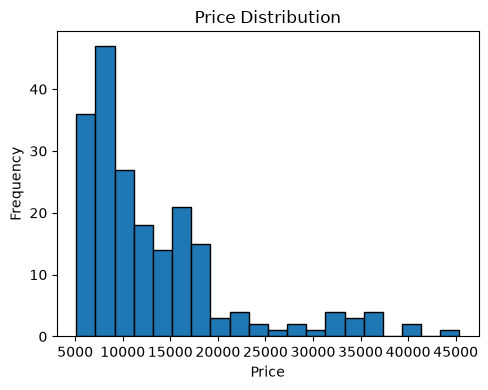

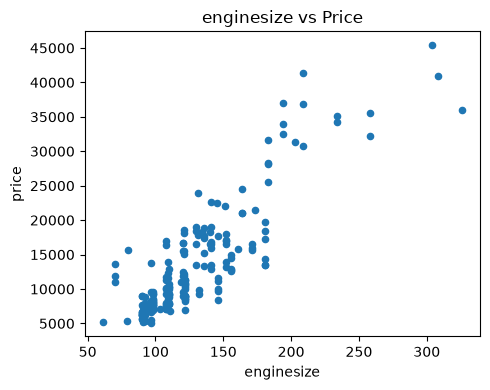

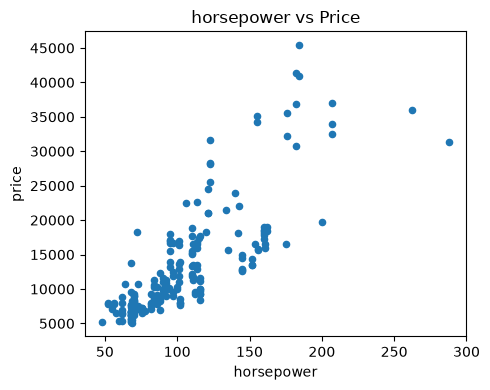

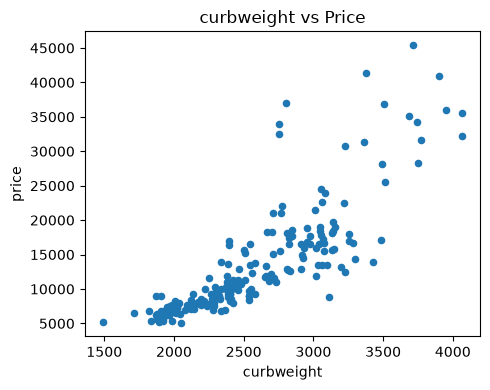

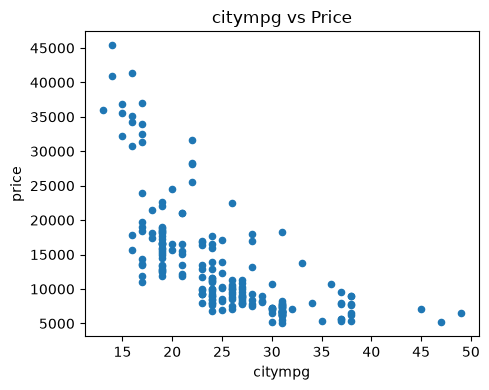

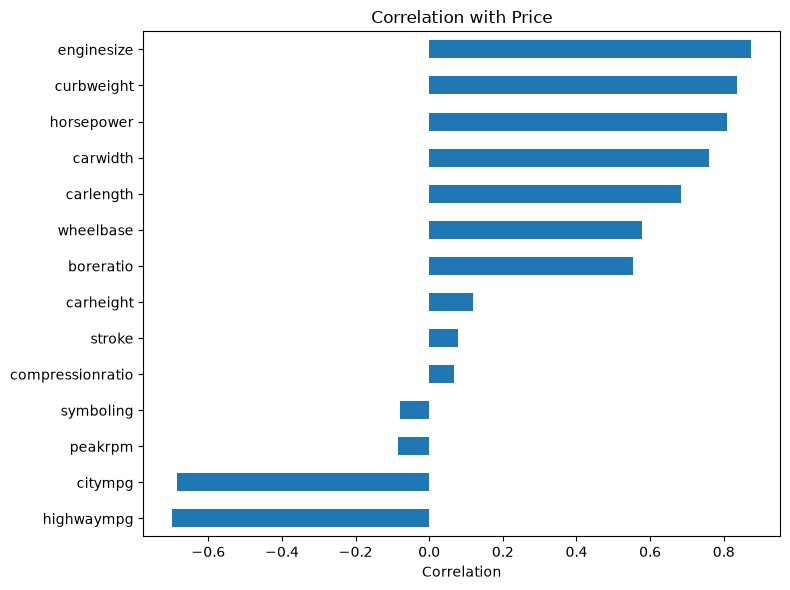

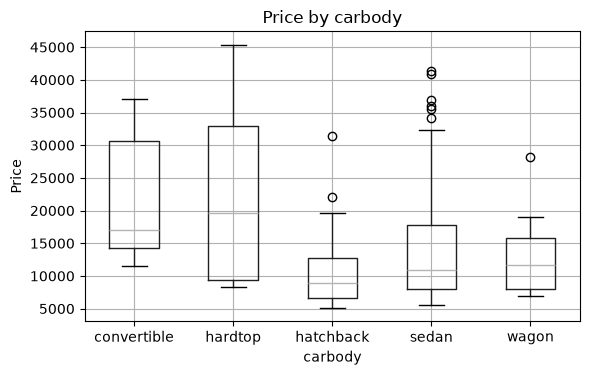

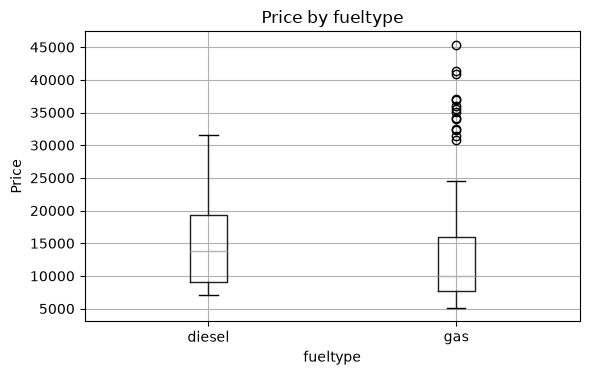

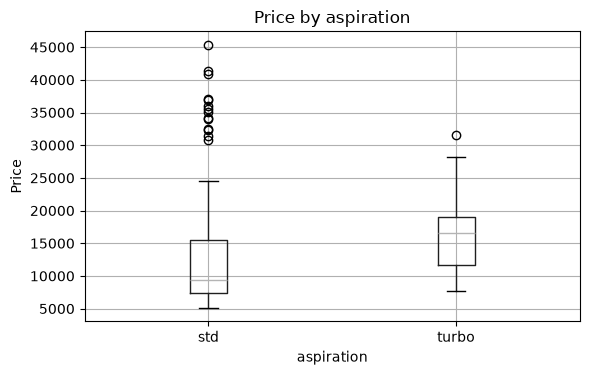

In [9]:
visualize_data(raw)

In [10]:
df = encode_features(raw)
print("Shape after encoding:", df.shape)
print("Missing values after encoding:", df.isnull().sum().sum())
print("Text columns left:", df.select_dtypes(exclude="number").columns.tolist())

X_train, X_test, y_train, y_test = split_xy(df)
X_train, X_test = standardize(X_train, X_test)
X_train = add_bias(X_train)
X_test = add_bias(X_test)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

Shape after encoding: (205, 65)
Missing values after encoding: 0
Text columns left: []
(164, 65) (41, 65) (164, 1) (41, 1)


In [11]:
w, losses = gradient_descent(X_train, y_train, lr=0.01, epochs=500)
print("Intercept w0:", round(w[0, 0], 2))

Intercept w0: 13285.33


In [12]:
pred_train = predict(X_train, w)
pred_test = predict(X_test, w)

results = pd.DataFrame({
    "Train": evaluate(y_train, pred_train),
    "Test": evaluate(y_test, pred_test)}).round(3)

results

,Train,Test
MAE,1156.858,1729.464
RMSE,1681.305,2634.133
R2,0.956,0.888


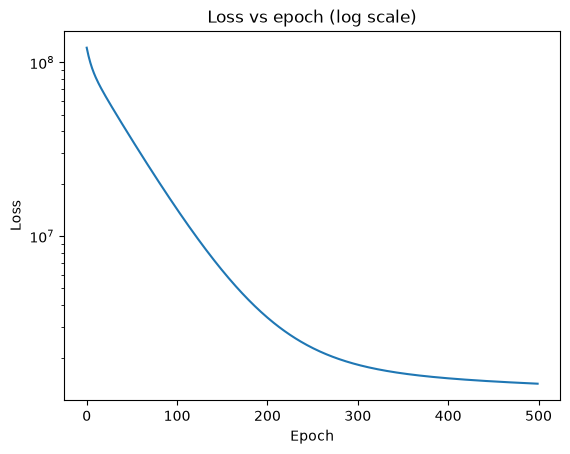

In [13]:
plot_loss(losses)

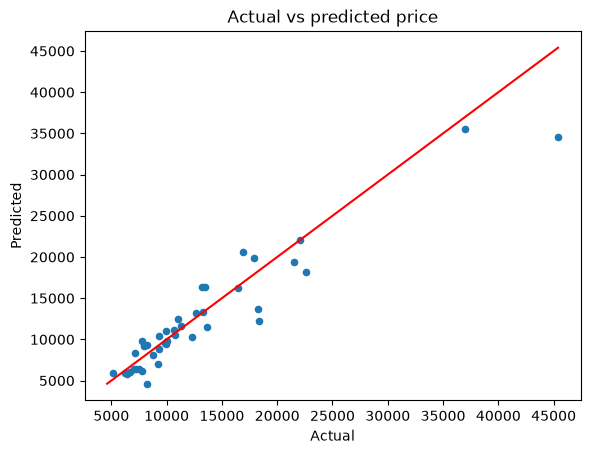

In [14]:
plot_predictions(y_test, pred_test)

In [15]:

deviations = pd.DataFrame({"Actual Price": y_test.ravel(), "Predicted Price": pred_test.ravel()})
deviations["Deviation"] = deviations["Predicted Price"] - deviations["Actual Price"]
deviations["Deviation %"] = (100 * deviations["Deviation"] / deviations["Actual Price"]).round(1)
deviations[["Actual Price", "Predicted Price", "Deviation"]] = deviations[["Actual Price", "Predicted Price", "Deviation"]].round(0).astype(int)
deviations.index = deviations.index + 1
deviations.index.name = "Test car"
print(deviations.to_string())

          Actual Price  Predicted Price  Deviation  Deviation %
Test car                                                       
1                 9279             8811       -468         -5.0
2                 9960             9442       -518         -5.2
3                 6377             5774       -603         -9.5
4                16925            20606       3681         21.7
5                 8778             8057       -721         -8.2
6                16500            16236       -264         -1.6
7                22018            22059         41          0.2
8                 7499             6379      -1120        -14.9
9                18344            12271      -6073        -33.1
10               10795            10489       -306         -2.8
11                6669             6084       -585         -8.8
12                8249             4623      -3626        -44.0
13                7053             6429       -624         -8.8
14               18280            13733 